# Imports

In [1]:
import os, sys
sys.path.append("D:\\DATA\\ETL_PIC\\simulation\\")
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
matplotlib.rc_file('D:\\DATA\\ETL_PIC\\matplotlibrc.txt')
import pandas as pd

import rsoft_lib as rlib
from rsoft_lib.device_setup import SIM, WIDTH, device_paths, scan_dir, export_device

# Design device

90° Euler s-bend side step. Always use ```R_min = 1400 μm``` and ```p = 0.5```.

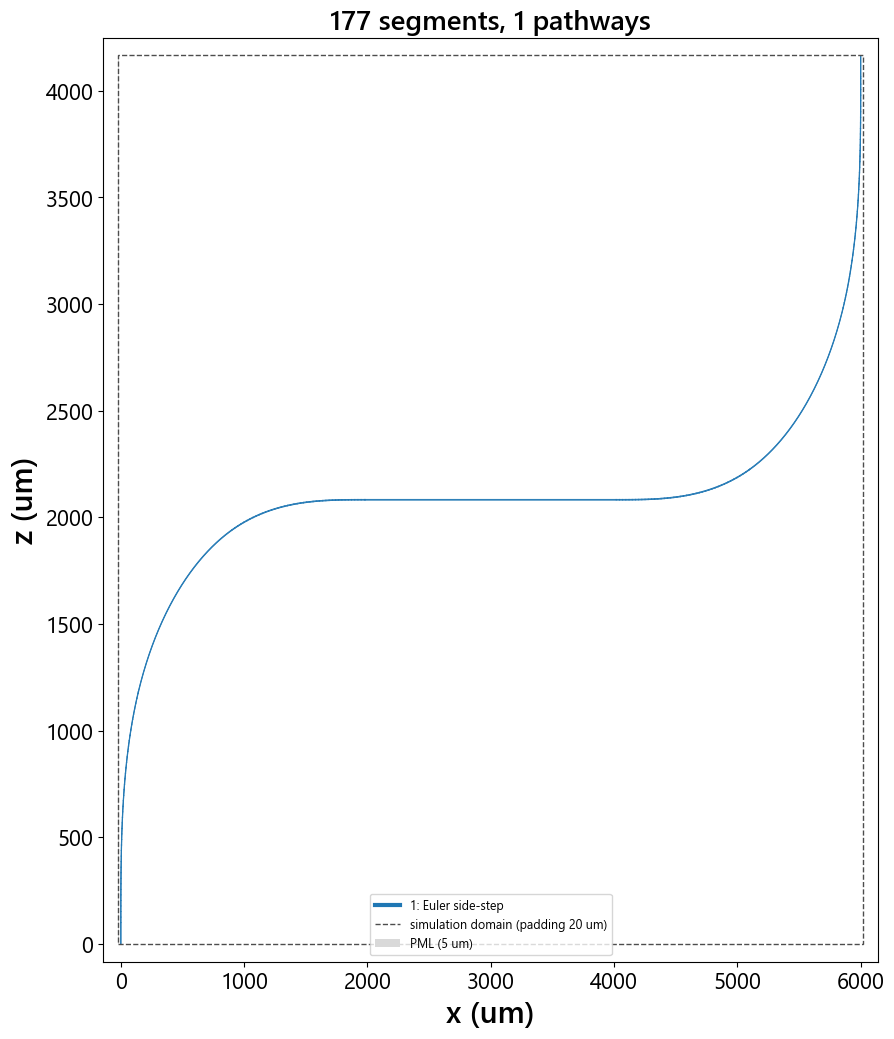

Euler side-step: 6000 μm offset, 90° bends (R_min 1400 μm, p 0.5), each bend 1982.8 μm across, straight 2034.5 μm, 3965.5 μm long in z
177 segments (0.95 nm from the curve); ends at (6000.0, 4165.500194393571)
Wrote D:\DATA\ETL_PIC\simulation\NullingPIC_Gen2_sims\A1-03_SideStep\A1-03_SideStep.ind and D:\DATA\ETL_PIC\simulation\NullingPIC_Gen2_sims\A1-03_SideStep\A1-03_SideStep.gds


In [2]:
# Set up directories
device_name = 'A1-03_SideStep'
device_dir = f"D:\\DATA\\ETL_PIC\\simulation\\NullingPIC_Gen2_sims\\{device_name}\\"
paths = device_paths(device_dir, device_name)

# Set up parameters
input_length = 100.0            # straight before the side-step (um)
output_length = 100.0           # straight after the side-step (um)
bend_radius = 1400.0            # minimum radius of the Euler bends (um)
euler_p = 0.5                   # Euler fraction: share of each bend that is clothoid ramp (0 circular, 1 pure Euler)
bend_angle = 90.0               # angle of each Euler bend (deg); the straight between them sets the offset
offset = 6000.0                 # lateral offset of the side-step (um)
fit_tol = 1e-3                  # largest deviation of the fitted arcs from the Euler curve (um)

# The Euler side-step from (0, input_length): Euler bend, straight at bend_angle, Euler bend back
xe, ze, pe, sidestep = rlib.euler_sidestep(bend_radius, bend_angle, euler_p, offset=offset, return_params=True)
ze = ze + input_length

# Define circuit: straight in, the side-step (fitted with arcs and lines), straight out
c = rlib.Circuit(width=WIDTH, orientation="extended")
lead = c.line((0.0, 0.0), (0.0, input_length))
bend = c.add_path(xe, ze, pe, tol=fit_tol)
x_out, z_bend = float(xe[-1]), float(ze[-1])
out = c.line((x_out, z_bend), (x_out, z_bend + output_length))
c.add_pathway([lead, *bend["segments"], out], launch=True)

# Export and visualize circuit
info = export_device(c, paths)
c.plot(labels=["Euler side-step"], figsize=(10, 12))
print(f"Euler side-step: {offset:g} μm offset, {bend_angle:g}° bends (R_min {bend_radius:g} μm, p {euler_p:g}), "
      f"each bend {sidestep['bend_offset']:.1f} μm across, straight {sidestep['straight']:.1f} μm, {sidestep['z_length']:.1f} μm long in z")
print(f"{len(c.pathways[0].segments)} segments ({bend['max_deviation'] * 1e3:.2f} nm from the curve); ends at {c.pathways[0].end}")
print(f"Wrote {paths['ind']} and {paths['gds']}")